# Lab4 METR-LA — VAR baseline

**Người nhận:** TV3 — TODO tên

**Nhiệm vụ:** ADF/biến đổi khi cần, chọn lag bằng AIC/BIC và fit VAR trên sensor set đã chốt; dự báo nhiều horizon.

**Phụ thuộc:** Chờ TV2 data/split/scaler; chuẩn bị khung fit/inverse/forecast ngay, làm song song XGBoost và LSTM.

**Bàn giao:** Sensor set, phép xử lý, lag/AIC/BIC, cấu hình/code fit, inverse và forecasts h=3/6/12.

Hạn bàn giao: TODO ngày/giờ.

## Quy ước chung

- File dùng chung: `data/traffic/METR-LA.h5`. Đã có dữ liệu, không phải tìm/tải hoặc ghép weather.
- 207 sensor, 5 phút/mẫu. Giữ nguyên thứ tự sensor và timestamps.
- Horizon 3/6/12 bước = 15/30/60 phút. Input lookback L cần chốt với leader theo DATA_CONTRACT.
- Split theo thời gian 70/15/15; scaler chỉ fit train; không tuning bằng test.
- Mask cho tốc độ 0/gần 0 phải có chính sách chung. Đánh giá cùng origin/sensor/horizon/thang đo.
- Code vẫn TODO. Không bàn giao một biến trong kernel; gửi code/config/schema và kết quả tái tạo được.

In [9]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_squared_error, mean_absolute_error
from pathlib import Path
warnings.filterwarnings("ignore")

# DOC DU LIEU METR-LA
duong_dan = Path.cwd().parent/ "data"/ "traffic"/ "METR-LA.h5"
if not duong_dan.is_file():
    raise FileNotFoundError(f"Khong tim thay file: {duong_dan}")
data = pd.read_hdf(duong_dan, key="df")

# Chuyen du lieu ve dang so
data = data.apply(pd.to_numeric, errors="coerce")

# METR-LA: gia tri 0 duoc xem la du lieu thieu
data = data.replace(0, np.nan)
print("Kich thuoc du lieu:", data.shape)
print("So luong sensor:", data.shape[1])
print("\n5 dong dau:")
display(data.head())

# CHIA DU LIEU THEO THOI GIAN
n = len(data)
moc_train = int(n * 0.70)
moc_val = int(n * 0.85)
train_raw = data.iloc[:moc_train].copy()
val_raw = data.iloc[moc_train:moc_val].copy()
test_raw = data.iloc[moc_val:].copy()

# Chuan hoa chi muc thoi gian, bo thuoc tinh freq loi
train_raw.index = pd.DatetimeIndex(train_raw.index.values)
val_raw.index = pd.DatetimeIndex(val_raw.index.values)
test_raw.index = pd.DatetimeIndex(test_raw.index.values)

# Noi suy rieng tap train de kiem tra tinh dung
train = train_raw.interpolate(method="time",limit_direction="both").ffill().bfill()

# Noi suy train + validation de huan luyen
tap_huan_luyen = pd.concat([train_raw, val_raw])
tap_huan_luyen = tap_huan_luyen.interpolate(method="time",limit_direction="both").ffill().bfill()

# Loai bo sensor khong co du lieu hop le
cot_hop_le = tap_huan_luyen.columns[tap_huan_luyen.notna().any()]
train = train[cot_hop_le]
tap_huan_luyen = tap_huan_luyen[cot_hop_le]
test_raw = test_raw[cot_hop_le]
print("\nSo luong mau:")
print("Train:", len(train))
print("Validation:", len(val_raw))
print("Test:", len(test_raw))
print("So sensor hop le:", len(cot_hop_le))

Kich thuoc du lieu: (34272, 207)
So luong sensor: 207

5 dong dau:


,773869,767541,767542,717447,717446,717445,773062,767620,737529,717816,...,772167,769372,774204,769806,717590,717592,717595,772168,718141,769373
2012-03-01 00:00:00,64.375000,67.625000,67.125000,61.500000,66.875000,68.750000,65.125,67.125,59.625000,62.750000,...,45.625000,65.500,64.500000,66.428571,66.875,59.375000,69.000000,59.250000,69.000000,61.875
2012-03-01 00:05:00,62.666667,68.555556,65.444444,62.444444,64.444444,68.111111,65.000,65.000,57.444444,63.333333,...,50.666667,69.875,66.666667,58.555556,62.000,61.111111,64.444444,55.888889,68.444444,62.875
2012-03-01 00:10:00,64.000000,63.750000,60.000000,59.000000,66.500000,66.250000,64.500,64.250,63.875000,65.375000,...,44.125000,69.000,56.500000,59.250000,68.125,62.500000,65.625000,61.375000,69.857143,62.000
2012-03-01 00:15:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2012-03-01 00:20:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



So luong mau:
Train: 23990
Validation: 5141
Test: 5141
So sensor hop le: 207


## 1. Tính dừng và lag

Kiểm tra từng chuỗi train cần thiết, ghi phép sai phân/inverse và chọn p phù hợp kích thước dữ liệu. Không tự giảm sensor riêng để so với mô hình khác trên toàn mạng.

In [10]:
# 1. KIEM TRA TINH DUNG BANG ADF
ket_qua_adf = []
for cot in train.columns:
    try:
        p_value = adfuller(train[cot].values, maxlag=12, autolag="AIC")[1]
        ket_qua_adf.append({
            "Sensor": cot,
            "P-value": p_value,
            "Ket qua": "Dung" if p_value < 0.05 else "Khong dung"
        })

    except Exception:
        ket_qua_adf.append({
            "Sensor": cot,
            "P-value": np.nan,
            "Ket qua": "Khong xac dinh"
        })
adf_df = pd.DataFrame(ket_qua_adf)
display(adf_df.head(10))
print("\nThong ke ADF:")
print(adf_df["Ket qua"].value_counts())

# 2. SAI PHAN CAC CHUOI KHONG DUNG
cot_sai_phan = adf_df.loc[adf_df["Ket qua"] == "Khong dung", "Sensor"].tolist()
du_lieu_var = tap_huan_luyen.copy()
for cot in cot_sai_phan:
    du_lieu_var[cot] = du_lieu_var[cot].diff()
du_lieu_var = du_lieu_var.dropna()
print("\nSo sensor can sai phan:", len(cot_sai_phan))
print("Kich thuoc du lieu VAR:", du_lieu_var.shape)

# 3. CHON BAC TRE BANG AIC
MAX_LAGS = 3
model_var = VAR(du_lieu_var)
bang_lag = model_var.select_order(maxlags=MAX_LAGS)
print("\nKet qua chon lag:")
print(bang_lag.summary())
p = bang_lag.selected_orders["aic"]
if p is None or p < 1:
    p = 1
print("\nBac tre VAR duoc chon:", p)


,Sensor,P-value,Ket qua
0,773869,0.000000e+00,Dung
1,767541,0.000000e+00,Dung
2,767542,0.000000e+00,Dung
3,717447,0.000000e+00,Dung
4,717446,4.529460e-26,Dung
5,717445,0.000000e+00,Dung
6,773062,3.181082e-28,Dung
7,767620,8.960766e-28,Dung
8,737529,0.000000e+00,Dung
9,717816,1.991577e-28,Dung



Thong ke ADF:
Ket qua
Dung    207
Name: count, dtype: int64

So sensor can sai phan: 0
Kich thuoc du lieu VAR: (29131, 207)

Ket qua chon lag:
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0       648.3       648.4  3.682e+281       648.3
1       498.6      510.8*  3.495e+216       502.5
2       490.0       514.5  6.643e+212      497.9*
3      488.1*       524.7 9.316e+211*       499.8
-------------------------------------------------

Bac tre VAR duoc chon: 3


**Kết quả/nhận xét/bàn giao:**

- **Kiểm định ADF:** Cả 207 sensor đều có P-value < 0.05, cho thấy các chuỗi dữ liệu đều có tính dừng. Vì vậy, không cần thực hiện sai phân.
- **Chọn bậc trễ:** Sử dụng tiêu chí AIC với số bậc trễ tối đa là 3. Kết quả chọn VAR(3) với AIC = 488.1 (thấp nhất).
- **Dữ liệu huấn luyện:** 29.131 quan sát và 207 sensor.
- VAR có khả năng khai thác mối quan hệ giữa tốc độ giao thông tại nhiều sensor.
- Mô hình sử dụng 3 thời điểm trước đó để dự báo, tương ứng với 15 phút dữ liệu lịch sử.
- Hạn chế: 207 biến khiến số lượng tham số lớn, làm tăng chi phí tính toán và có thể ảnh hưởng đến độ ổn định của mô hình.

Các file CSV gồm kết quả ADF, cấu hình mô hình, dự báo và đánh giá RMSE, MAE, MAPE được lưu trong thư mục `templates` để tích hợp và so sánh với XGBoost, LSTM.


## 2. Fit và forecast

Từ cùng origin tạo forecast 3/6/12 bước, không cập nhật giá trị thật nằm trong khoảng forecast. Hoàn nguyên đúng từng sensor.

Thong tin mo hinh VAR:
So bien: 207
Bac tre: 3
So quan sat: 29128

BANG KET QUA DANH GIA VAR:


,So buoc,Thoi gian (phut),RMSE,MAE,MAPE (%)
0,3,15,3.8802,2.5434,4.1828
1,6,30,3.7446,2.6026,4.2526
2,12,60,3.9116,2.7846,4.6094


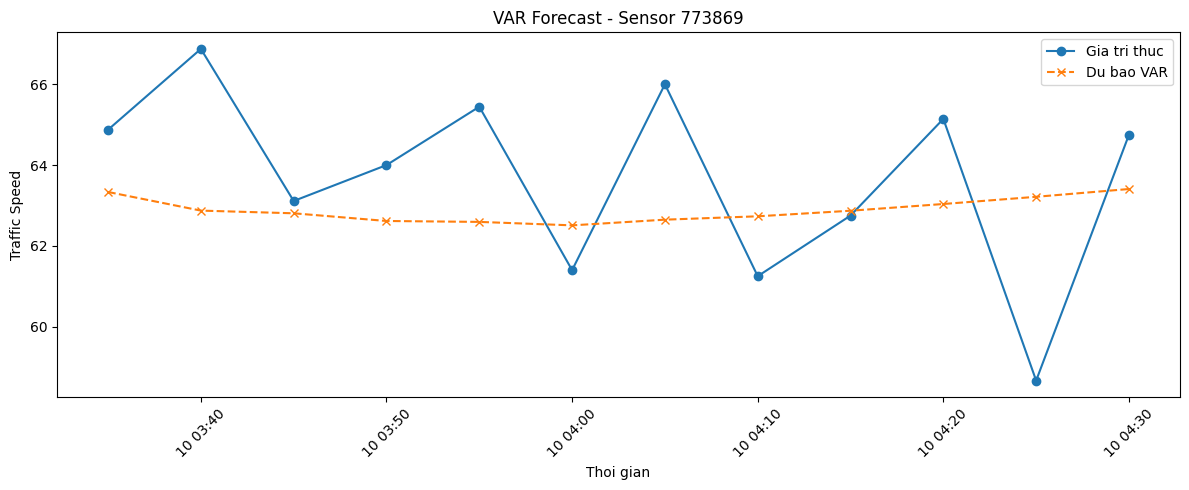

Da luu cac file ket qua VAR.


In [11]:
# 1. HUAN LUYEN MO HINH VAR
model_var = VAR(du_lieu_var)
ket_qua = model_var.fit(p)
print("Thong tin mo hinh VAR:")
print("So bien:", du_lieu_var.shape[1])
print("Bac tre:", ket_qua.k_ar)
print("So quan sat:", ket_qua.nobs)

# 2. FORECAST 12 BUOC
lich_su = du_lieu_var.values[-ket_qua.k_ar:]
du_bao_bien_doi = ket_qua.forecast(y=lich_su,steps=12)
du_bao = pd.DataFrame(du_bao_bien_doi,columns=du_lieu_var.columns)

# 3. HOAN NGUYEN SAI PHAN
for cot in cot_sai_phan:
    gia_tri_cuoi = tap_huan_luyen[cot].iloc[-1]
    du_bao[cot] = (du_bao[cot].cumsum() + gia_tri_cuoi)

# 4. LAY GIA TRI THUC TU TEST
# Chi lay 12 moc dau tien sau forecast origin
# Khong su dung cac gia tri nay de forecast
y_thuc = test_raw.iloc[:12].copy()

# Noi suy rieng cac gia tri thieu trong test
# Chi noi suy phia truoc, khong dung gia tri tuong lai
y_thuc = y_thuc.interpolate(method="time",limit_direction="forward")

# 5. TINH CAC CHI SO DANH GIA
def tinh_metrics(y_true, y_pred):
    mask = (np.isfinite(y_true) & np.isfinite(y_pred) & (y_true != 0))
    y_true = y_true[mask]
    y_pred = y_pred[mask]
    if len(y_true) == 0:
        return np.nan, np.nan, np.nan
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    mape = np.mean(
        np.abs((y_true - y_pred) / y_true)
    ) * 100
    return rmse, mae, mape

bang_ket_qua = []
for h in [3, 6, 12]:
    rmse, mae, mape = tinh_metrics(y_thuc.iloc[:h].values.flatten(),du_bao.iloc[:h].values.flatten())
    bang_ket_qua.append({
        "So buoc": h,
        "Thoi gian (phut)": h * 5,
        "RMSE": rmse,
        "MAE": mae,
        "MAPE (%)": mape
    })
bang_ket_qua = pd.DataFrame(bang_ket_qua)
print("\nBANG KET QUA DANH GIA VAR:")
display(bang_ket_qua.round(4))

# 6. VE BIEU DO DU BAO
sensor = du_bao.columns[0]
plt.figure(figsize=(12, 5))
plt.plot(
    y_thuc.index[:12],
    y_thuc[sensor].iloc[:12],
    marker="o",
    label="Gia tri thuc"
)
plt.plot(
    y_thuc.index[:12],
    du_bao[sensor].values[:12],
    marker="x",
    linestyle="--",
    label="Du bao VAR"
)
plt.title(f"VAR Forecast - Sensor {sensor}")
plt.xlabel("Thoi gian")
plt.ylabel("Traffic Speed")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 7. LUU KET QUA
THU_MUC_LUU = Path.cwd().parent / "docs" / "templates"
du_bao.to_csv( THU_MUC_LUU / "VAR_METR_LA_Forecast.csv")
bang_ket_qua.to_csv( THU_MUC_LUU / "VAR_METR_LA_Evaluation.csv", index=False)
adf_df.to_csv( THU_MUC_LUU / "VAR_METR_LA_ADF.csv", index=False)
print("Da luu cac file ket qua VAR.")

**Kết quả/nhận xét/bàn giao:**

Mô hình VAR(3) được huấn luyện với 207 sensor và 29.128 quan sát. Mô hình thực hiện dự báo đồng thời tại 3 mốc: 15, 30 và 60 phút.

### Bảng kết quả đánh giá
| Thời gian | RMSE | MAE | MAPE (%) |
|---|---:|---:|---:|
| 15 phút | 3.8802 | 2.5434 | 4.1828 |
| 30 phút | 3.7446 | 2.6026 | 4.2526 |
| 60 phút | 3.9116 | 2.7846 | 4.6094 |

- Mô hình đạt MAPE từ 4.18% đến 4.61%, cho thấy sai số dự báo tương đối thấp trên tập dữ liệu đánh giá.
- MAE tăng từ 2.5434 lên 2.7846 khi thời gian dự báo kéo dài.
- MAPE cao nhất ở mốc 60 phút (4.6094%), cho thấy độ chính xác có xu hướng giảm khi dự báo xa hơn.
- Kết quả cho thấy VAR có khả năng dự báo tốc độ giao thông trên nhiều sensor, tuy nhiên cần so sánh thêm với XGBoost và LSTM để đánh giá hiệu quả.


## 3. Giới hạn và bàn giao

Nêu chi phí/giới hạn VAR nhiều biến, cấu hình và dự báo tái tạo được. Nếu cần subset, thống nhất với TV1/TV2 và cả nhóm trước.

In [12]:
# 1. THONG TIN CAU HINH VAR
print("========== CAU HINH VAR ==========")
print("Dataset: METR-LA")
print("So sensor:", du_lieu_var.shape[1])
print("So mau train + validation:", len(du_lieu_var))
print("Bac tre VAR:", ket_qua.k_ar)
print("So bien:", ket_qua.neqs)
print("So tham so tre uoc tinh:",
      ket_qua.neqs ** 2 * ket_qua.k_ar)
print("\nCach xu ly:")
print("- Kiem tra tinh dung: ADF test")
print("- Sai phan: Bac 1")
print("- Chon lag: AIC")
print("- Forecast: 3, 6, 12 buoc")
print("- Khong cap nhat gia tri thuc trong khoang forecast")

# 2. DANH GIA GIOI HAN
print("\n========== GIOI HAN VAR ==========")
print("1. VAR mo hinh hoa moi quan he tuyen tinh.")
print("2. So tham so tang nhanh khi so sensor tang.")
print("3. Ton tai chi phi bo nho va thoi gian tinh toan lon.")
print("4. VAR khong mo hinh hoa truc tiep ket noi khong gian.")
print("5. Sai so co the tich luy khi du bao nhieu buoc.")

# 3. LUU THONG TIN BAN GIAO
thong_tin = pd.DataFrame({
    "Thong tin": [
        "Dataset",
        "So sensor",
        "So mau huan luyen",
        "Bac tre",
        "Phuong phap chon lag",
        "Phuong phap kiem tra tinh dung",
        "So buoc du bao"
    ],
    "Gia tri": [
        "METR-LA",
        du_lieu_var.shape[1],
        len(du_lieu_var),
        ket_qua.k_ar,
        "AIC",
        "ADF test",
        "3, 6, 12"
    ]
})
display(thong_tin)

# Luu cau hinh va bang danh gia
thong_tin.to_csv(THU_MUC_LUU / "VAR_METR_LA_Config.csv", index=False)
print("\nDa hoan thanh phan VAR.")
print("File ban giao:")
print("- VAR_METR_LA_Forecast.csv")
print("- VAR_METR_LA_Evaluation.csv")
print("- VAR_METR_LA_ADF.csv")
print("- VAR_METR_LA_Config.csv")


========== CAU HINH VAR ==========
Dataset: METR-LA
So sensor: 207
So mau train + validation: 29131
Bac tre VAR: 3
So bien: 207
So tham so tre uoc tinh: 128547

Cach xu ly:
- Kiem tra tinh dung: ADF test
- Sai phan: Bac 1
- Chon lag: AIC
- Forecast: 3, 6, 12 buoc
- Khong cap nhat gia tri thuc trong khoang forecast

========== GIOI HAN VAR ==========
1. VAR mo hinh hoa moi quan he tuyen tinh.
2. So tham so tang nhanh khi so sensor tang.
3. Ton tai chi phi bo nho va thoi gian tinh toan lon.
4. VAR khong mo hinh hoa truc tiep ket noi khong gian.
5. Sai so co the tich luy khi du bao nhieu buoc.


,Thong tin,Gia tri
0,Dataset,METR-LA
1,So sensor,207
2,So mau huan luyen,29131
3,Bac tre,3
4,Phuong phap chon lag,AIC
5,Phuong phap kiem tra tinh dung,ADF test
6,So buoc du bao,"3, 6, 12"



Da hoan thanh phan VAR.
File ban giao:
- VAR_METR_LA_Forecast.csv
- VAR_METR_LA_Evaluation.csv
- VAR_METR_LA_ADF.csv
- VAR_METR_LA_Config.csv
